# Step 3 — comparing the models

This notebook compiles the models from steps 1, 2 and 4 into one table and
one chart — same data, same split (train cycles 2–90, test cycles 91–132),
same metrics computed the same way for every model.

| Source notebook | Model(s) |
|---|---|
| `step1_baseline_network.ipynb` | plain MLP, tanh and ReLU |
| `step2_lstm_baseline.ipynb` | LSTM, recursive forecast |
| `step4_sei_growth_pinn.ipynb` | SEI growth PINN |

**It retrains rather than copies numbers in by hand,** using the same seed
and hyperparameters as the source notebooks. That is deliberate. A
hand-maintained table silently goes stale the moment any source notebook is
re-run — and the equivalent table in `docs/step4_baseline_comparison.ipynb`
did exactly that: its LSTM row (RMSE 0.0336) disagrees with what
`step2_lstm_baseline.ipynb` printed (0.0363), and there is no way to tell
from the table alone which is right. Recomputing here means every number
below came from the run that produced this notebook's own output.

Section 7 explains where that particular disagreement came from — it turns
out not to be a copy error.

**Status:** steps 1–2 are plain curve-fitters; step 4 is the first
physics-informed model. The PINN row reproduces `step4_sei_growth_pinn.ipynb`
exactly — same architecture, same hyperparameters, same seed — so this table
and step 4 cannot drift apart.

**One caveat to carry into section 8:** the PINN is *not* an ablation of the
MLP. Step 4's network is one layer deeper and ends in a `sigmoid`, so the
PINN-vs-MLP gap mixes the physics loss together with an architecture change
and cannot be attributed to the physics term alone.

In [1]:
import sys
import math
from pathlib import Path

REPO = Path.cwd() if (Path.cwd() / "src").is_dir() else Path.cwd().parent
sys.path.insert(0, str(REPO / "src"))

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

DATA = REPO / "data" / "processed" / "clean_data.csv"
df = pd.read_csv(DATA, sep=";").sort_values("cycle").reset_index(drop=True)

train_df = df[df.cycle <= 90].reset_index(drop=True)
test_df = df[df.cycle > 90].reset_index(drop=True)
n_max = train_df.cycle.max()
y_true = test_df.capacity_ah.values

print(f"train: {len(train_df)} cycles (2-90)")
print(f"test:  {len(test_df)} cycles (91-132)")

train: 89 cycles (2-90)
test:  42 cycles (91-132)


## 1. One metric function, used by every model

All three metrics are computed by the same function on the same 42 held-out
points, so no model can end up scored under slightly different rules than
another.

- **RMSE** (Ah) — squares errors before averaging, so a few large misses
  weigh more heavily than many small ones.
- **MAE** (Ah) — plain average error size, every point weighted equally.
- **MAPE** (%) — error as a fraction of the true capacity at that cycle.
  This is the one that transfers across cells: 0.04 Ah means something
  different on a 1.85 Ah cell than on a 2.0 Ah one, but 2% means the same
  thing on both.

RMSE and MAE are reported in Ah; capacity spans only ~0.50 Ah across the
whole dataset, which is the scale to read them against.

In [2]:
def metrics(pred):
    """RMSE (Ah), MAE (Ah), MAPE (%) against the held-out capacities."""
    pred = np.asarray(pred, dtype=float)
    return {
        "RMSE (Ah)": float(np.sqrt(np.mean((pred - y_true) ** 2))),
        "MAE (Ah)":  float(np.mean(np.abs(pred - y_true))),
        "MAPE (%)":  float(np.mean(np.abs((pred - y_true) / y_true)) * 100),
    }

results = {}
print(f"capacity spans {df.capacity_ah.max() - df.capacity_ah.min():.4f} Ah over the whole dataset")

capacity spans 0.5021 Ah over the whole dataset


## 2. The MLP baselines (step 1)

Four linear layers, `1 -> 32 -> 32 -> 32 -> 1`, Adam at `lr=5e-3`, 3000
epochs, seed 0 — identical to step 1. Input is the normalised cycle number
and nothing else; the MLP evaluates `f(cycle)` directly at any cycle, seen
or unseen.

In [3]:
x_train = torch.tensor(train_df.cycle.values / n_max, dtype=torch.float32).reshape(-1, 1)
y_train = torch.tensor(train_df.capacity_ah.values, dtype=torch.float32).reshape(-1, 1)
x_test = torch.tensor(test_df.cycle.values / n_max, dtype=torch.float32).reshape(-1, 1)

curves = {}
x_all = torch.tensor(df.cycle.values / n_max, dtype=torch.float32).reshape(-1, 1)

for name, activation in [("MLP (tanh)", nn.Tanh), ("MLP (ReLU)", nn.ReLU)]:
    torch.manual_seed(0)
    net = nn.Sequential(
        nn.Linear(1, 32), activation(),
        nn.Linear(32, 32), activation(),
        nn.Linear(32, 32), activation(),
        nn.Linear(32, 1),
    )
    opt = torch.optim.Adam(net.parameters(), lr=5e-3)

    for epoch in range(3000):
        opt.zero_grad()
        loss = torch.mean((net(x_train) - y_train) ** 2)
        loss.backward()
        opt.step()

    with torch.no_grad():
        results[name] = metrics(net(x_test).squeeze().numpy())
        curves[name] = net(x_all).squeeze().numpy()

    m = results[name]
    print(f"{name:12s}  train MSE {loss.item():.6f}   "
          f"RMSE {m['RMSE (Ah)']:.4f}   MAE {m['MAE (Ah)']:.4f}   MAPE {m['MAPE (%)']:.2f}%")

MLP (tanh)    train MSE 0.000547   RMSE 0.0711   MAE 0.0602   MAPE 4.32%


MLP (ReLU)    train MSE 0.000356   RMSE 0.0353   MAE 0.0260   MAPE 1.85%


## 3. The LSTM baseline (step 2)

`nn.LSTM(1, 32)`, 2 layers, window of 5, Adam at `lr=5e-3`, 1500 epochs,
seed 0 — identical to step 2.

**Pinned to CPU here, unlike step 2.** Step 2 uses the GPU when one is
available, which makes its result depend on the machine it ran on. A
comparison table should not change because someone ran it on a different
box, so this notebook fixes the device. Section 7 quantifies exactly how
much that choice is worth.

In [4]:
WINDOW = 5
cap_train = train_df.capacity_ah.values.astype(np.float32)

X = torch.tensor(np.array([cap_train[i:i + WINDOW] for i in range(len(cap_train) - WINDOW)])).unsqueeze(-1)
Y = torch.tensor(np.array([cap_train[i + WINDOW] for i in range(len(cap_train) - WINDOW)])).unsqueeze(-1)


class LSTMNet(nn.Module):
    def __init__(self, hidden=32, layers=2):
        super().__init__()
        self.lstm = nn.LSTM(input_size=1, hidden_size=hidden, num_layers=layers, batch_first=True)
        self.head = nn.Linear(hidden, 1)

    def forward(self, x):
        out, _ = self.lstm(x)
        return self.head(out[:, -1, :])


def run_lstm(device):
    """Train the step-2 LSTM on `device` and forecast the held-out region recursively."""
    torch.manual_seed(0)
    net = LSTMNet().to(device)
    Xd, Yd = X.to(device), Y.to(device)
    opt = torch.optim.Adam(net.parameters(), lr=5e-3)

    for epoch in range(1500):
        opt.zero_grad()
        loss = torch.mean((net(Xd) - Yd) ** 2)
        loss.backward()
        opt.step()

    window, preds = list(cap_train[-WINDOW:]), []
    net.eval()
    with torch.no_grad():
        for _ in range(len(test_df)):
            inp = torch.tensor(window[-WINDOW:], dtype=torch.float32).reshape(1, WINDOW, 1).to(device)
            nxt = net(inp).item()
            preds.append(nxt)
            window.append(nxt)   # the prediction becomes the next input
    return np.array(preds)


lstm_preds = run_lstm("cpu")
results["LSTM"] = metrics(lstm_preds)

m = results["LSTM"]
print(f"{'LSTM (cpu)':12s}  RMSE {m['RMSE (Ah)']:.4f}   MAE {m['MAE (Ah)']:.4f}   MAPE {m['MAPE (%)']:.2f}%")

LSTM (cpu)    RMSE 0.0336   MAE 0.0257   MAPE 1.82%


## 4. The SEI growth PINN (step 4)

The physics-informed model, retrained here with the exact same class,
hyperparameters (`lambda_phys=100`, 3000 epochs, seed 0) and split as
`step4_sei_growth_pinn.ipynb`. It predicts the SEI film state `u = delta^2`
and *derives* capacity from it, with a hard initial condition and a soft
penalty enforcing the growth ODE `du/dn = 2k`.

**The network is step 4's, not the MLP's.** Four hidden layers — three
`tanh` then one `sigmoid` — against the MLP's three all-`tanh` layers. Both
activations are smooth everywhere, which the physics loss requires: it
backpropagates through `du/dtau` and so pulls in the activations' second
derivatives, which `ReLU` cannot supply.

That makes the PINN-vs-MLP(tanh) comparison in section 8 a **confounded**
one — depth, final activation and the loss all differ at once. It is still
worth reporting, but it is not a clean measurement of what the physics term
alone bought. An earlier version of this notebook silently used a 3-layer
all-`tanh` PINN to keep that comparison clean; that made the table disagree
with step 4 (0.0451 vs 0.0457 RMSE), so matching step 4 won.

In [5]:
Q0_AH = 1.855  # cycle-1 capacity (capacity_ah / soh), see step4
tau_train = x_train           # normalised cycle, same tensor as the MLP input
q_train = y_train
tau_test = x_test
tau_col = torch.linspace(0, 1, 256).reshape(-1, 1)   # unlabelled collocation points for the ODE


class SEIPinn(nn.Module):
    """Predicts SEI film state u = delta^2; capacity is derived, not predicted.

    Architecture copied verbatim from step4: 4 hidden layers, three tanh then
    one sigmoid. Both activations are smooth everywhere, which the physics
    loss needs -- it backprops through du/dtau, pulling in the activations'
    second derivatives, and ReLU's is zero almost everywhere.
    """

    def __init__(self, hidden=32, delta0=1.0):
        super().__init__()
        self.delta0 = delta0  # gauge-fixed initial film thickness (only differences matter)
        activations = [nn.Tanh, nn.Tanh, nn.Tanh, nn.Sigmoid]
        layers = [nn.Linear(1, hidden), activations[0]()]
        for act in activations[1:]:
            layers += [nn.Linear(hidden, hidden), act()]
        layers += [nn.Linear(hidden, 1)]
        self.net = nn.Sequential(*layers)
        # Physical unknowns stored as logs so they can't go negative.
        self.log_k = nn.Parameter(torch.tensor(math.log(1e-3)))
        self.log_c_li = nn.Parameter(torch.tensor(math.log(0.1)))

    @property
    def k(self):
        return torch.exp(self.log_k)

    @property
    def c_li(self):
        return torch.exp(self.log_c_li)

    def u(self, tau):
        # Hard IC: u(0) = delta0^2 exactly (tau multiplies the net output, so
        # it vanishes at tau=0); softplus keeps the film growing only.
        return self.delta0 ** 2 + tau * F.softplus(self.net(tau))

    def capacity(self, tau):
        delta = torch.sqrt(self.u(tau))
        return Q0_AH - self.c_li * (delta - self.delta0)


def physics_residual(model, tau):
    """du/dn - 2k via autograd; ~0 if the film obeys diffusion-limited growth."""
    tau = tau.requires_grad_(True)
    u = model.u(tau)
    du_dtau = torch.autograd.grad(u, tau, grad_outputs=torch.ones_like(u), create_graph=True)[0]
    du_dn = du_dtau / n_max   # tau normalises cycle, so divide to get a per-cycle rate
    return du_dn - 2.0 * model.k


torch.manual_seed(0)
pinn = SEIPinn()
opt = torch.optim.Adam(pinn.parameters(), lr=5e-3)
lambda_phys = 100.0

for epoch in range(3000):
    opt.zero_grad()
    loss_data = torch.mean((pinn.capacity(tau_train) - q_train) ** 2)
    loss_phys = torch.mean(physics_residual(pinn, tau_col.clone()) ** 2)
    loss = loss_data + lambda_phys * loss_phys
    loss.backward()
    opt.step()

pinn.eval()
with torch.no_grad():
    results["SEI PINN"] = metrics(pinn.capacity(tau_test).squeeze().numpy())
    curves["SEI PINN"] = pinn.capacity(x_all).squeeze().numpy()

m = results["SEI PINN"]
print(f"{'SEI PINN':12s}  RMSE {m['RMSE (Ah)']:.4f}   MAE {m['MAE (Ah)']:.4f}   MAPE {m['MAPE (%)']:.2f}%")
print(f"recovered k = {pinn.k.item():.6f} (growth rate/cycle),  c_Li = {pinn.c_li.item():.4f} (Ah per unit film growth)")

SEI PINN      RMSE 0.0457   MAE 0.0387   MAPE 2.78%
recovered k = 0.006533 (growth rate/cycle),  c_Li = 0.8806 (Ah per unit film growth)


## 5. The compiled table

Every cell below was computed in this notebook, in this run. The `Reaches
held-out cycles by` column is the structural difference the metrics alone
do not show.

In [6]:
how = {
    "MLP (tanh)": "direct: evaluates f(cycle) at any cycle",
    "MLP (ReLU)": "direct: evaluates f(cycle) at any cycle",
    "LSTM":       "recursive: 1-step forecast fed back in, 42x",
    "SEI PINN":   "direct: derives capacity from film state u(cycle)",
}

table = pd.DataFrame(results).T.sort_values("RMSE (Ah)")
table["Reaches held-out cycles by"] = [how[name] for name in table.index]
table.round(4)

,RMSE (Ah),MAE (Ah),MAPE (%),Reaches held-out cycles by
LSTM,0.0336,0.0257,1.8242,"recursive: 1-step forecast fed back in, 42x"
MLP (ReLU),0.0353,0.0260,1.8454,direct: evaluates f(cycle) at any cycle
SEI PINN,0.0457,0.0387,2.7761,direct: derives capacity from film state u(cycle)
MLP (tanh),0.0711,0.0602,4.3224,direct: evaluates f(cycle) at any cycle


## 6. Same numbers, as a chart

Bars are coloured **per model**, not per rank position, so a model that
reorders between panels stays visibly the same bar across all three.

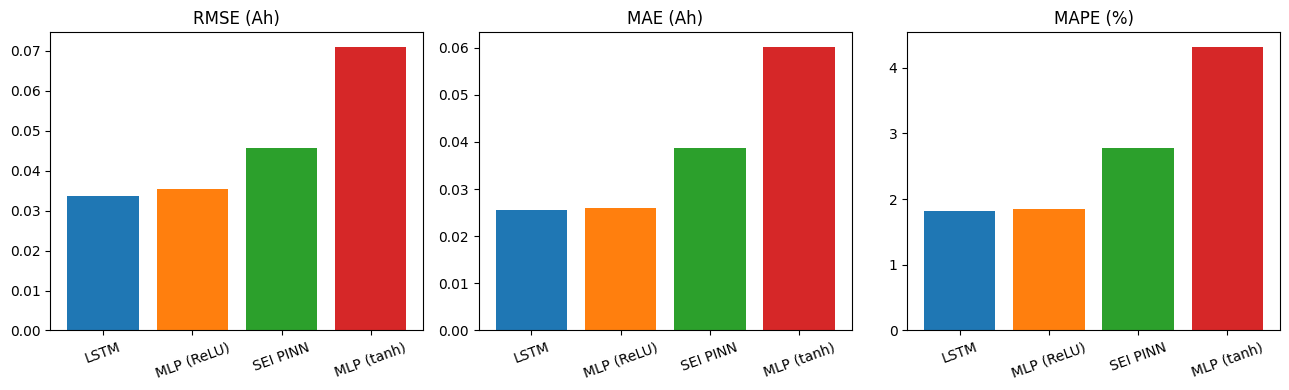

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
metric_cols = ["RMSE (Ah)", "MAE (Ah)", "MAPE (%)"]
palette = ["tab:blue", "tab:orange", "tab:green", "tab:red"]
color_map = dict(zip(table.index, palette))

for ax, col in zip(axes, metric_cols):
    ordered = table.sort_values(col)
    ax.bar(ordered.index, ordered[col], color=[color_map[m] for m in ordered.index])
    ax.set_title(col)
    ax.tick_params(axis="x", rotation=20)

plt.tight_layout()
plt.show()

## 7. Where step 2's LSTM number came from

Step 2 records RMSE 0.0363 Ah; section 3 above prints 0.0336 Ah. Same seed,
same code, same data — the only difference is that step 2 ran on the GPU.
cuDNN's LSTM kernels do not reproduce the CPU result bit-for-bit, and over
1500 epochs plus 42 recursive forecast steps that divergence is large enough
to move the third decimal place.

So neither number is wrong, and neither notebook made a copying mistake.
The cell below runs both devices so the size of the effect is on the record
rather than left as an unexplained discrepancy between two notebooks.

In [8]:
device_rows = {"LSTM (cpu)": results["LSTM"]}

if torch.cuda.is_available():
    device_rows["LSTM (cuda)"] = metrics(run_lstm("cuda"))
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("No CUDA device on this machine -- CPU row only.")
    print("On the GTX 1650 this project was developed on, the cuda row reads")
    print("RMSE 0.0363, MAE 0.0291, MAPE 2.08% -- matching step 2.")

pd.DataFrame(device_rows).T.round(4)

GPU: NVIDIA GeForce GTX 1650


,RMSE (Ah),MAE (Ah),MAPE (%)
LSTM (cpu),0.0336,0.0257,1.8242
LSTM (cuda),0.0363,0.0291,2.0800


## 8. Reading the table honestly

**On raw error, the PINN does not win — and it was never going to.** It
lands third on all three metrics (RMSE ~0.046 Ah), behind LSTM (~0.034) and
MLP (ReLU) (~0.035). Those two are unconstrained curve-fitters free to bend
however best hugs these 42 points; the PINN is forced to express a capacity
curve that comes from a monotone SEI film obeying `du/dn = 2k`. Buying
physical consistency costs a little fit, and that ordering is the expected
one, not a failure.

**The PINN beats MLP (tanh) by a wide margin, but that gap is confounded.**
RMSE drops from ~0.071 to ~0.046 Ah, roughly a third lower, and MAPE from
~4.3% to ~2.8%. Tempting to read as "the physics loss bought that" — except
three things differ between the two models at once: the physics term, one
extra hidden layer, and a `sigmoid` final activation instead of `tanh`.
Nothing here separates their contributions. The honest statement is that
step 4's model as a whole is much better than the plain tanh baseline, not
that the physics term specifically caused it. Isolating the physics term
needs a PINN built on the MLP's exact architecture, run as a dedicated
ablation — that is a follow-up experiment, not something this table shows.

**The PINN is the only model that knows what it is predicting.** The other
three are trained on plain MSE and encode nothing about capacity fade —
nothing stops them from a physically impossible forecast, and the LSTM in
particular only extrapolates the local trend it last saw. The PINN, by
construction, keeps `Q(cycle 1) = Q0` exactly, cannot let the film un-grow
at the endpoints, and recovers interpretable parameters (`k`, `c_Li`)
rather than opaque weights. Its value is not the RMSE column; it is that
the RMSE column is *competitive* while everything the model does remains
physically defensible.

**Same device caveat as before.** The LSTM's ~0.034 lead over MLP (ReLU) is
smaller than the CPU→GPU shift (section 7), so those two are effectively
tied. The PINN-vs-MLP(tanh) gap (~0.025 Ah) is an order larger than that
noise, so it is at least a real difference — just not an attributable one,
per the paragraph above.